<a href="https://colab.research.google.com/github/alwinbshaji/Data-Science/blob/main/CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Convolutoin neural network to classify handwritten digits using MNIST dataset

In [9]:
from keras.datasets import mnist
import matplotlib.pyplot as plt

In [10]:
#load the mnist datasets already splitted data
(x_train,y_train),(x_test,y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


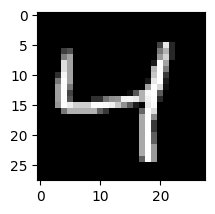

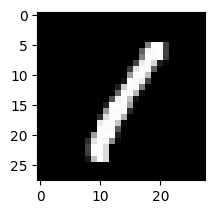

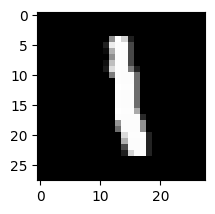

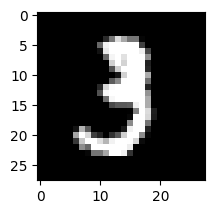

In [11]:
#instead of directly printig the array ,we will plot some
#images for checking from our dataset
#we will create a 2X2 grid to display 4 images
plt.subplot(221)  #the 1st img to be displayed in a 2x2 grid
plt.imshow(x_train[2] , cmap=plt.get_cmap('gray'))
plt.show()

plt.subplot(222)  #the 1st img to be displayed in a 2x2 grid
plt.imshow(x_train[3] , cmap=plt.get_cmap('gray'))
plt.show()

plt.subplot(223)  #the 1st img to be displayed in a 2x2 grid
plt.imshow(x_train[6] , cmap=plt.get_cmap('gray'))
plt.show()

plt.subplot(224)  #the 1st img to be displayed in a 2x2 grid
plt.imshow(x_train[10] , cmap=plt.get_cmap('gray'))
plt.show()

In [12]:
print(y_train[2])
print(y_train[3])
print(y_train[6])
print(y_train[10])

4
1
1
3


In [13]:
#before we can pass the image for training we need
#to reshape the image into [data][channels][with][height]
#for training ,rows will be 6000,testing rows will be 10000
#we can get the rows using eg:x_train.shape[0]
x_train = x_train.reshape(x_train.shape[0],28,28,1).astype('float32')
x_test = x_test.reshape(x_test.shape[0],28,28,1).astype('float32')

In [14]:
# normalize the input from 0 to 255 range to 0 to 1 range
# to do that, divide all numbers using 255

x_train = x_train/255
x_test = x_test/255

In [15]:
from keras.utils import to_categorical

In [16]:

# onehot encode the output data
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

num_classes = 10

In [17]:
#creqting a base line for CNN

In [18]:
from keras.models import Sequential
from keras.layers import Conv2D,MaxPool2D,Dropout,Flatten,Dense

In [19]:
#create a function for defining base neutral base neutral netwrok
def baseline_model():
  #create a sequential model object
  mymodel = Sequential()
  #add a convolution layer with 32 feature map and 5x5 filter
  mymodel.add(Conv2D(32,(5,5),padding='valid',input_shape=(28,28,1),activation='relu'))
  #add a pooling layer with a pool size of 2x2
  mymodel.add(MaxPool2D(pool_size=(2,2)))
  #add a dropout layer with a dropout rate 0.2 to prevetn overfit
  mymodel.add(Dropout(0.2))


  #now we can proceed with a deep neutral netwrk for classification
  #to give the 2d feature map as inpit tothe neutral network
  #we need to flatten the data
  mymodel.add(Flatten())

  #TYPICAL DEEP NEUTRAL NETORK FOR CLASSIFICATION-------------
  #add a normal neural netwrok input layer
  mymodel.add(Dense(128,activation='relu'))

  #add am output layer with 10 classes
  #use softmax activation fn to ,ulti class classification
  mymodel.add(Dense(10,activation='softmax'))

  #compile the model and return the model
  mymodel.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
  return mymodel

In [20]:
#build the model
mymodel = baseline_model()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#fir the model with training and testing data
mymodel.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=10,batch_size=200,verbose=2)

Epoch 1/10
300/300 - 36s - 118ms/step - accuracy: 0.9255 - loss: 0.2605 - val_accuracy: 0.9751 - val_loss: 0.0840
Epoch 2/10
300/300 - 32s - 106ms/step - accuracy: 0.9769 - loss: 0.0765 - val_accuracy: 0.9839 - val_loss: 0.0506
Epoch 3/10
300/300 - 33s - 110ms/step - accuracy: 0.9839 - loss: 0.0531 - val_accuracy: 0.9854 - val_loss: 0.0428
Epoch 4/10
300/300 - 39s - 131ms/step - accuracy: 0.9880 - loss: 0.0403 - val_accuracy: 0.9869 - val_loss: 0.0396
Epoch 5/10
